In [1]:
#Image imports
from pathlib import Path
from PIL import Image
import torch

#VLM imports
# from transformers import pipeline
from transformers import AutoProcessor, AutoModelForMultimodalLM
# from datasets import load_dataset
import matplotlib.pyplot as plt

#Streaming imports
import time
from threading import Thread
from transformers import TextIteratorStreamer

#Schema validation imports
import json
import re
from typing import Literal
from pydantic import BaseModel, Field, ValidationError, field_validator

#Environment imports
from dotenv import load_dotenv
load_dotenv() 

W1022 16:12:17.668000 41951 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


True

In [2]:
img_path = Path("../data/test-penguin.jpeg")
img = Image.open(img_path)

In [3]:
processor = AutoProcessor.from_pretrained("Qwen/Qwen3.5-2B")
model = AutoModelForMultimodalLM.from_pretrained("Qwen/Qwen3.5-2B", device_map="auto")

Loading weights:   0%|          | 0/617 [00:00<?, ?it/s]

In [4]:
print(model.device)

mps:0


In [5]:
prompt = """
Detect every penguin in the image.
For each penguin, return a JSON object with:
  "bbox_2d": [x1, y1, x2, y2] (coordinates normalized to 0-1000),
  "label": "penguin",
  "sub_label": species or "" if unknown
Return a JSON array only, with no other text.
"""

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": img},
            {"type": "text", "text": prompt}
        ]
    },
] 

inputs = processor.apply_chat_template(
	messages,
	add_generation_prompt=True,
	tokenize=True,
	return_dict=True,
	return_tensors="pt",
).to(model.device)

In [13]:
streamer = TextIteratorStreamer(
    processor.tokenizer,
    skip_prompt=True,
    skip_special_tokens=True,
)

# keep a place for the tensor generate returns
result = {}

def run():
    result["sequences"] = model.generate(
        **inputs,
        max_new_tokens=1024,
        streamer=streamer,
    )

t0 = time.perf_counter()
thread = Thread(target=run)
thread.start()

for piece in streamer:
    print(piece, end="", flush=True)

thread.join()
T = time.perf_counter() - t0

L_prompt = inputs["input_ids"].shape[-1]
L_out = result["sequences"].shape[-1]
N = L_out - L_prompt

print()
print("N [New tokens] =", N)
print("T [Wall time] =", T)
print("N/T [Throughput] =", N / T, "tok/s")

```json
[
	{"bbox_2d": [74, 350, 217, 619], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [241, 298, 377, 608], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [273, 248, 398, 542], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [388, 265, 450, 400], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [410, 238, 462, 325], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [411, 353, 529, 612], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [452, 300, 536, 545], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [478, 232, 532, 475], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [516, 303, 594, 550], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [536, 237, 599, 370], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [570, 348, 714, 630], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [574, 255, 660, 435],

In [14]:
#Dry run for plots
json = [
	{"bbox_2d": [74, 350, 217, 619], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [241, 298, 377, 608], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [273, 248, 398, 542], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [388, 265, 450, 400], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [410, 238, 462, 325], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [411, 353, 529, 612], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [452, 300, 536, 545], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [478, 232, 532, 475], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [516, 303, 594, 550], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [536, 237, 599, 370], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [570, 348, 714, 630], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [574, 255, 660, 435], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [652, 242, 704, 465], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [698, 275, 754, 512], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [716, 248, 760, 315], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [730, 320, 852, 585], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [764, 255, 826, 480], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [834, 310, 986, 623], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [868, 232, 978, 365], "label": "penguin", "sub_label": "Gentoo penguin"},
	{"bbox_2d": [898, 320, 998, 542], "label": "penguin", "sub_label": "Gentoo penguin"}
]

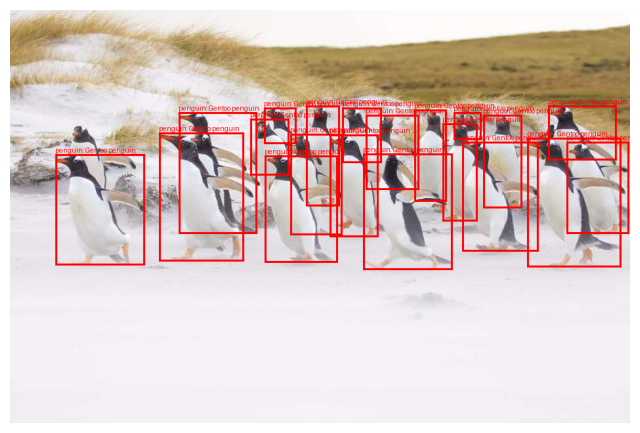

In [15]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

def norm1000_to_pixels(bbox, w, h):
    x1, y1, x2, y2 = bbox
    return [
        int(x1 / 1000 * w),
        int(y1 / 1000 * h),
        int(x2 / 1000 * w),
        int(y2 / 1000 * h),
    ]

img = Image.open("../data/test-penguin.jpeg").convert("RGB")
w, h = img.size
vis = img.copy()
draw = ImageDraw.Draw(vis)

for d in json:
    x1, y1, x2, y2 = norm1000_to_pixels(d["bbox_2d"], w, h)
    draw.rectangle([x1, y1, x2, y2], outline="red", width=3)
    sub = d.get("sub_label") or ""
    label = d["label"] if not sub else f'{d["label"]}: {sub}'
    draw.text((x1, max(0, y1 - 12)), label, fill="red")

plt.figure(figsize=(8, 8))
plt.imshow(vis)
plt.axis("off")
plt.show()

In [8]:
def validate_penguin_detections(text: str) -> list[dict]:
    """Extract JSON array from model text and check a simple penguin schema."""
    match = re.search(r"\[.*\]", text, flags=re.S)
    if not match:
        raise ValueError("No JSON array found in model output")

    data = json.loads(match.group(0))
    if not isinstance(data, list):
        raise ValueError("Top-level JSON must be a list")

    validated = []
    for i, item in enumerate(data):
        if not isinstance(item, dict):
            raise ValueError(f"Item {i} is not an object")

        if "bbox_2d" not in item or "label" not in item:
            raise ValueError(f"Item {i} missing bbox_2d or label")

        bbox = item["bbox_2d"]
        if not (isinstance(bbox, list) and len(bbox) == 4):
            raise ValueError(f"Item {i}: bbox_2d must be [x1, y1, x2, y2]")

        x1, y1, x2, y2 = bbox
        if not all(isinstance(c, (int, float)) and 0 <= c <= 1000 for c in bbox):
            raise ValueError(f"Item {i}: coords must be numbers in [0, 1000]")
        if x2 <= x1 or y2 <= y1:
            raise ValueError(f"Item {i}: need x2 > x1 and y2 > y1")

        if item["label"] != "penguin":
            raise ValueError(f"Item {i}: label must be 'penguin'")

        validated.append({
            "bbox_2d": [float(x1), float(y1), float(x2), float(y2)],
            "label": "penguin",
            "sub_label": str(item.get("sub_label", "")),
        })

    return validated

In [9]:
dets = validate_penguin_detections(json)
print(dets)

TypeError: expected string or bytes-like object, got 'module'

In [ ]:
def norm1000_to_pixels(bbox, w, h):
    x1, y1, x2, y2 = bbox
    return [
        int(x1 / 1000 * w),
        int(y1 / 1000 * h),
        int(x2 / 1000 * w),
        int(y2 / 1000 * h),
    ]
img = Image.open("../data/test-penguin.jpeg").convert("RGB")  # same image you sent to the model
w, h = img.size
vis = img.copy()
draw = ImageDraw.Draw(vis)
for d in dets:
    x1, y1, x2, y2 = norm1000_to_pixels(d.bbox_2d, w, h)
    draw.rectangle([x1, y1, x2, y2], outline="red", width=3)
    label = d.label if not d.sub_label else f"{d.label}: {d.sub_label}"
    draw.text((x1, max(0, y1 - 12)), label, fill="red")
plt.figure(figsize=(8, 8))
plt.imshow(vis)
plt.axis("off")
plt.show()